# Explainability — SwinV2-Small Two-Phase Best

**EEEM068 Applied Machine Learning — Group Coursework**

Runs independently from the training notebook. Only requires the saved checkpoint at
`outputs/swinv2_twophase_best/checkpoints/phase2_best.pt`.

| Section | Technique |
|---|---|
| 1 | Setup — install, paths, model, predictions |
| 2 | Per-grade sample images (Kaggle-style visual) |
| 3 | Grad-CAM++ — spatial heatmaps |
| 4 | Per-grade Grad-CAM gallery |
| 5 | Attention Rollout — native SwinV2 attention |
| 6 | Grade 1 false negatives — clinically critical |
| 7 | LIME — superpixel explanations |
| 8 | Misclassification analysis |
| 9 | Confidence calibration |
| 10 | Summary |

## 1. Setup

In [129]:
# ── Install explainability dependencies into the active venv ──────────────────
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install',
                'grad-cam', 'lime', 'scikit-image', 'opencv-python-headless',
                '--quiet'], check=True)
print('Dependencies installed ✓')

Dependencies installed ✓


In [130]:
import os, random, sys
from pathlib import Path

import cv2
import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
# Import calibration_curve from the correct module
from sklearn.calibration import calibration_curve

# Your existing metrics imports
from sklearn.metrics import (
    confusion_matrix, cohen_kappa_score,
    f1_score, precision_score, recall_score, accuracy_score,
)


print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

PyTorch : 2.11.0+cu130
timm    : 1.0.26
CUDA    : True


In [131]:
# ── Paths — mirror training notebook exactly ──────────────────────────────────
NOTEBOOK_DIR = Path().resolve()
ROOT         = NOTEBOOK_DIR.parent

DATA_ROOT = ROOT / 'data' / 'diabetic-retinopathy-detection'
TEST_DIR  = DATA_ROOT / 'test_labels_proc'
TEST_CSV  = DATA_ROOT / 'test_split.csv'

OUT_DIR   = ROOT / 'outputs' / 'swinv2_twophase_best'
CKPT_BEST = OUT_DIR / 'checkpoints' / 'phase2_best.pt'
FIG_DIR   = OUT_DIR / 'figures'
XAI_DIR   = OUT_DIR / 'explainability'
for d in (FIG_DIR, XAI_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Constants — same as training notebook ─────────────────────────────────────
SEED        = 42
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
DR_COLORS   = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#8e44ad']
IMAGE_SIZE  = 256
SWIN_MEAN   = (0.485, 0.456, 0.406)
SWIN_STD    = (0.229, 0.224, 0.225)
DROPOUT     = 0.3
BATCH_SIZE  = 16
NUM_WORKERS = 4
MODEL_NAME  = 'swinv2_small_window8_256'
WEIGHTS_PATH = ROOT / 'weights' / 'swinv2_small.safetensors'

print(f'Checkpoint : {CKPT_BEST}')
print(f'XAI output : {XAI_DIR}')

Checkpoint : /scratch/AML_G14_CW/outputs/swinv2_twophase_best/checkpoints/phase2_best.pt
XAI output : /scratch/AML_G14_CW/outputs/swinv2_twophase_best/explainability


In [132]:
# ── Seed + device ─────────────────────────────────────────────────────────────
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device:', device)

Device: cuda


In [133]:
# ── Dataset class — same as training notebook ──────────────────────────────────
class DRDataset(Dataset):
    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# val_transform — same as training notebook (no augmentation, centre crop only)
val_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.05)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(SWIN_MEAN, SWIN_STD),
])

test_df     = pd.read_csv(TEST_CSV)
test_ds     = DRDataset(test_df, TEST_DIR, transform=val_transform)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'Test set: {len(test_ds):,} images  |  {len(test_loader)} batches')

Test set: 5,269 images  |  330 batches


In [134]:
# ── Model — same build function as training notebook ──────────────────────────
def _load_swin_weights(backbone: nn.Module, weights_path: str) -> None:
    from timm.models._helpers import load_checkpoint
    result = load_checkpoint(backbone, weights_path, strict=False)
    n_head = len([k for k in result.missing_keys    if 'custom_head' in k])
    n_skip = len([k for k in result.unexpected_keys if 'head.fc' in k or 'attn_mask' in k])
    print(f'  Weights loaded — head keys (random init): {n_head}, old keys ignored: {n_skip}')


def build_swin_model(pretrained: bool = True) -> nn.Module:
    backbone = timm.create_model(
        MODEL_NAME, pretrained=False, num_classes=0, global_pool='avg')
    feat_dim = backbone.num_features
    backbone.custom_head = nn.Sequential(
        nn.LayerNorm(feat_dim),
        nn.Dropout(p=DROPOUT),
        nn.Linear(feat_dim, NUM_CLASSES),
    )
    _base = backbone.forward
    backbone.forward = lambda x: backbone.custom_head(_base(x))

    wp = Path(str(WEIGHTS_PATH)) if WEIGHTS_PATH else None
    if wp and wp.exists():
        print(f'Loading local weights: {wp.name}')
        _load_swin_weights(backbone, str(wp))
    elif pretrained:
        try:
            print('Downloading pretrained weights from HuggingFace...')
            tmp    = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0, global_pool='avg')
            own_sd = backbone.state_dict()
            src_sd = {k: v for k, v in tmp.state_dict().items()
                      if k in own_sd and 'custom_head' not in k}
            own_sd.update(src_sd)
            backbone.load_state_dict(own_sd, strict=False)
            del tmp
        except Exception as e:
            print(f'Download failed: {e}'); raise
    else:
        print('Random init.')

    print(f'SwinV2-Small | {sum(p.numel() for p in backbone.parameters())/1e6:.1f}M params')
    return backbone


# ── FocalLoss — same as training notebook ─────────────────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0):
        super().__init__()
        self.gamma = gamma
    def forward(self, logits, target):
        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        return ((1.0 - pt) ** self.gamma * ce).mean()

In [135]:
# ── Load best checkpoint ──────────────────────────────────────────────────────
model     = build_swin_model(pretrained=False).to(device)
criterion = FocalLoss(gamma=2.0)
ckpt      = torch.load(CKPT_BEST, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
model.eval()
print(f'Loaded: {CKPT_BEST.name}  epoch={ckpt["epoch"]}  val_kappa={ckpt["val_kappa"]:.4f}')

Random init.
SwinV2-Small | 49.0M params
Loaded: phase2_best.pt  epoch=7  val_kappa=0.6570


In [136]:
# ── Collect all test-set predictions in one forward pass ─────────────────────
# All downstream sections use these three arrays — no repeated inference.
all_probs, all_preds, all_labels = [], [], []

model.eval()
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc='Collecting predictions'):
        probs = F.softmax(model(imgs.to(device)), dim=1).cpu().numpy()
        all_probs.append(probs)
        all_preds.append(probs.argmax(axis=1))
        all_labels.append(labels.numpy())

all_probs  = np.concatenate(all_probs,  axis=0)   # (N, 5)
all_preds  = np.concatenate(all_preds,  axis=0)   # (N,)
all_labels = np.concatenate(all_labels, axis=0)   # (N,)

print(f'Test samples : {len(all_preds):,}')
print(f'Accuracy     : {(all_preds == all_labels).mean():.3f}')
print(f'QWK          : {cohen_kappa_score(all_labels, all_preds, weights="quadratic"):.4f}')

Test samples : 5,269
Accuracy     : 0.704
QWK          : 0.6778


In [137]:
# ── Image helper utilities ────────────────────────────────────────────────────
def get_tensor(ds, idx):
    """Return ((1,C,H,W) tensor on device, int label)."""
    img, label = ds[idx]
    return img.unsqueeze(0).to(device), int(label)


def get_pil(ds, idx):
    """Return (PIL Image, int label) by un-normalising the stored tensor.
    No dependency on df column names.
    """
    tensor, label = ds[idx]
    mean = torch.tensor(SWIN_MEAN).view(3, 1, 1)
    std  = torch.tensor(SWIN_STD).view(3, 1, 1)
    img  = (tensor.cpu() * std + mean).clamp(0, 1)
    return TF.to_pil_image(img), int(label)


def to_np(pil_or_tensor, size=224):
    """PIL or (C,H,W) tensor -> float32 numpy (H,W,3) in [0,1]."""
    if isinstance(pil_or_tensor, torch.Tensor):
        arr = pil_or_tensor.cpu().numpy().transpose(1, 2, 0)
    else:
        arr = np.array(pil_or_tensor.resize((size, size))) / 255.0
    arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)
    return arr.astype(np.float32)


# Quick sanity check
pil, lbl = get_pil(test_ds, 0)
print(f'get_pil OK — label={lbl}  size={pil.size}')

# Convenient index references used throughout
correct_idx = int(np.where(all_preds == all_labels)[0][0])
wrong_idx   = int(np.where(all_preds != all_labels)[0][0])
print('Helpers defined ✓')

get_pil OK — label=0  size=(256, 256)
Helpers defined ✓


---
## 2. Per-Grade Sample Images

Mirrors the Kaggle winner's opening section: the 3 most confident correct test predictions per grade, raw images only. Sets clinical context before any gradient-based explanation.

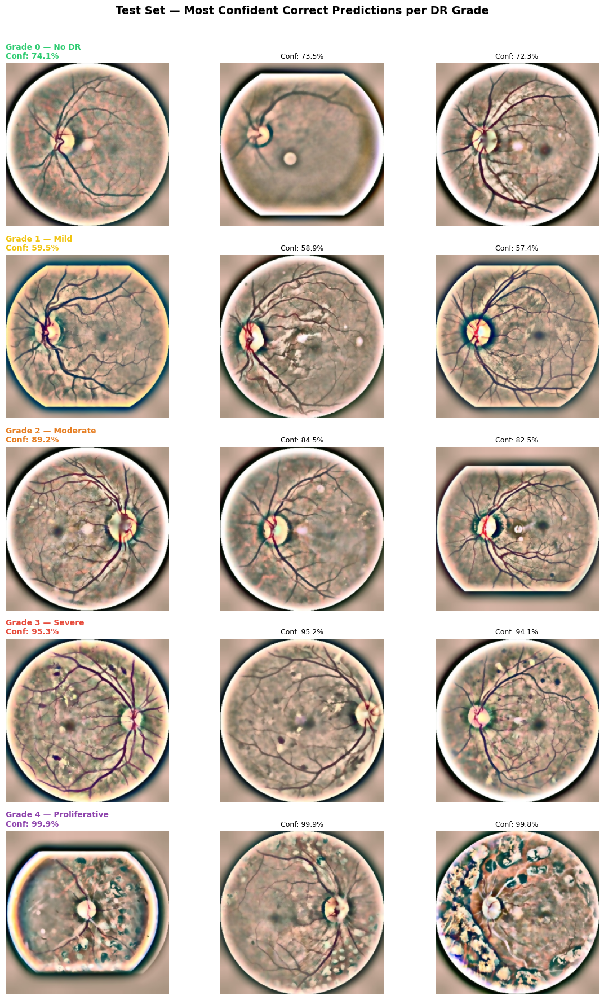

Saved -> /scratch/AML_G14_CW/outputs/swinv2_twophase_best/explainability/per_grade_samples.png


In [138]:
N = 3
fig, axes = plt.subplots(5, N, figsize=(N * 4, 5 * 3.5))
fig.suptitle('Test Set — Most Confident Correct Predictions per DR Grade',
             fontsize=14, fontweight='bold', y=1.01)

for grade in range(5):
    mask    = (all_labels == grade) & (all_preds == grade)
    indices = np.where(mask)[0]
    if len(indices) == 0:
        print(f'Grade {grade}: no correct predictions found.')
        for col in range(N): axes[grade, col].axis('off')
        continue
    top_idx = indices[np.argsort(all_probs[indices, grade])[::-1][:N]]

    for col, idx in enumerate(top_idx):
        ax = axes[grade, col]
        ax.imshow(get_pil(test_ds, int(idx))[0])
        ax.axis('off')
        conf = all_probs[idx, grade]
        if col == 0:
            ax.set_title(f'Grade {grade} — {CLASS_NAMES[grade]}\nConf: {conf*100:.1f}%',
                         fontsize=10, fontweight='bold', color=DR_COLORS[grade], loc='left')
        else:
            ax.set_title(f'Conf: {conf*100:.1f}%', fontsize=9)

plt.tight_layout()
fig.savefig(XAI_DIR / 'per_grade_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {XAI_DIR / "per_grade_samples.png"}')

---
## 3. Grad-CAM++ — Spatial Heatmaps

Highlights which retinal regions drove each prediction. The `swin_reshape_transform` handles both `(B, N, C)` token-sequence and `(B, C, H, W)` spatial outputs from `model.norm`, making it robust to different timm versions.

In [139]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def swin_reshape_transform(tensor):
    """Convert SwinV2 norm output to (B, C, H, W) for Grad-CAM.
    Handles both (B, N, C) token sequence and (B, C, H, W) spatial output.
    """
    if tensor.ndim == 4:
        return tensor                              # already spatial
    B, N, C = tensor.shape
    H = W   = int(N ** 0.5)
    assert H * W == N, f'Non-square patch grid: N={N}'
    return tensor.reshape(B, H, W, C).permute(0, 3, 1, 2)


# Initialised once globally — never inside a plot function (causes hook leak)
# Target the last SwinV2 stage's last block norm instead of model.norm
# This sits inside the backbone where gradients flow correctly
target_layers = [model.layers[-1].blocks[-1].norm1]

cam = GradCAMPlusPlus(
    model=model,
    target_layers=target_layers,
    reshape_transform=swin_reshape_transform,
)
print(f'Grad-CAM++ target: layers[-1].blocks[-1].norm1 ✓')

Grad-CAM++ target: layers[-1].blocks[-1].norm1 ✓


=== Correct prediction ===


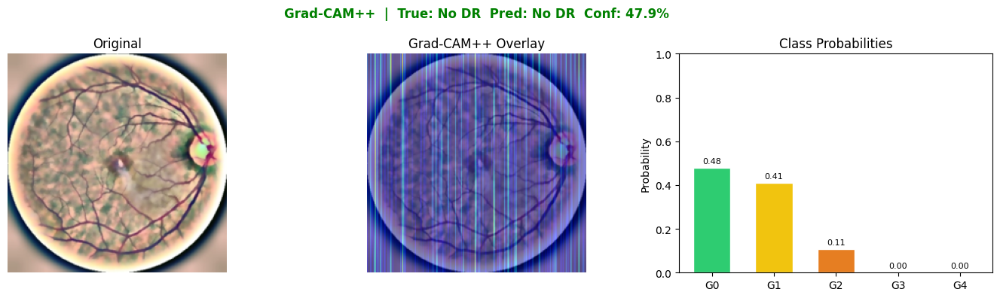

=== Misclassified sample ===


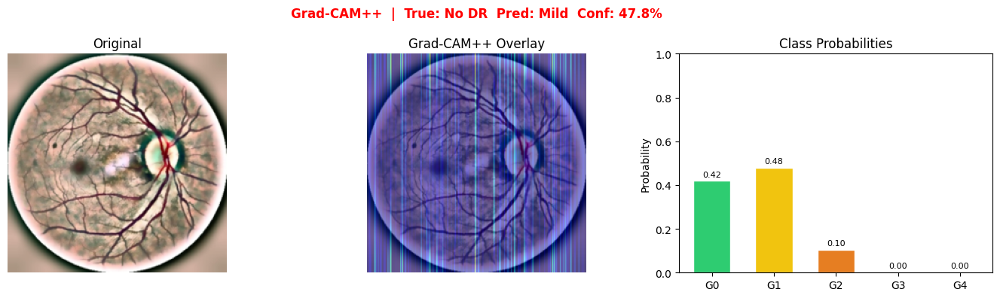

In [140]:
def gradcam_plot(ds, idx, save_path=None):
    tensor, label = get_tensor(ds, idx)
    pil, _        = get_pil(ds, idx)
    rgb_np        = to_np(pil)                        # whatever size get_pil returns

    with torch.no_grad():
        probs = F.softmax(model(tensor), dim=1).cpu().numpy()[0]
    pred    = int(probs.argmax())
    heatmap = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(pred)])[0]

    # Resize heatmap to match rgb_np — handles any size mismatch automatically
    h, w    = rgb_np.shape[:2]
    heatmap = cv2.resize(heatmap, (w, h))
    overlay = show_cam_on_image(rgb_np, heatmap, use_rgb=True)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    fig.suptitle(
        f'Grad-CAM++  |  True: {CLASS_NAMES[label]}  '
        f'Pred: {CLASS_NAMES[pred]}  Conf: {probs[pred]*100:.1f}%',
        fontsize=12, fontweight='bold',
        color='green' if pred == label else 'red'
    )
    axes[0].imshow(rgb_np);   axes[0].set_title('Original');           axes[0].axis('off')
    axes[1].imshow(overlay);  axes[1].set_title('Grad-CAM++ Overlay'); axes[1].axis('off')

    bars = axes[2].bar(range(5), probs, color=DR_COLORS, edgecolor='white', width=0.6)
    axes[2].set_xticks(range(5))
    axes[2].set_xticklabels([f'G{i}' for i in range(5)])
    axes[2].set_ylabel('Probability'); axes[2].set_ylim(0, 1)
    axes[2].set_title('Class Probabilities')
    for bar, p in zip(bars, probs):
        axes[2].text(bar.get_x() + bar.get_width()/2, p + 0.02,
                     f'{p:.2f}', ha='center', fontsize=8)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


print('=== Correct prediction ===')
gradcam_plot(test_ds, correct_idx, XAI_DIR / 'gradcam_correct.png')
print('=== Misclassified sample ===')
gradcam_plot(test_ds, wrong_idx,   XAI_DIR / 'gradcam_wrong.png')

---
## 4. Per-Grade Grad-CAM Gallery

For each DR grade, the 3 most confident correct predictions with Grad-CAM overlays. Shows what retinal features the model associates with each severity level — the primary report figure.

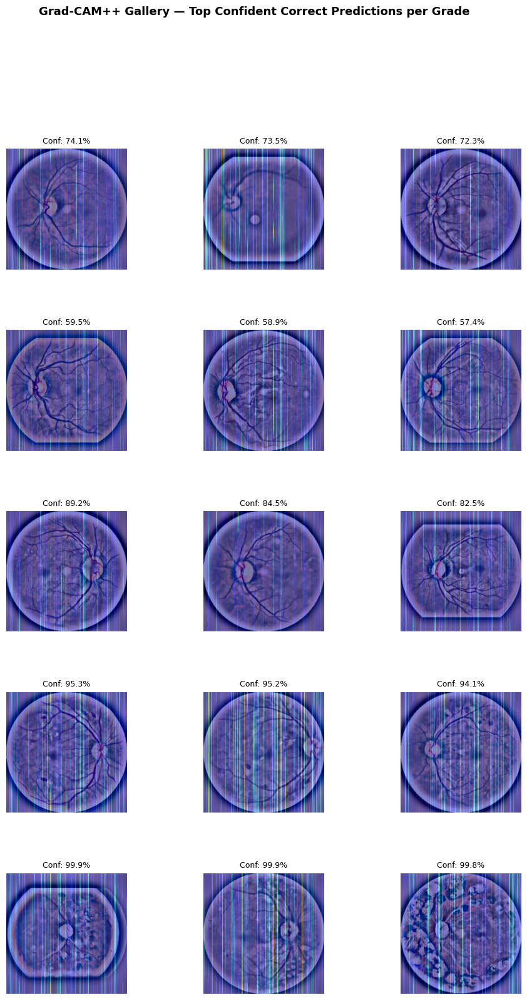

In [141]:
N = 3
fig = plt.figure(figsize=(N * 4, 5 * 3.5))
fig.suptitle('Grad-CAM++ Gallery — Top Confident Correct Predictions per Grade',
             fontsize=13, fontweight='bold', y=1.01)
outer = gridspec.GridSpec(5, 1, figure=fig, hspace=0.5)

for grade in range(5):
    mask    = (all_labels == grade) & (all_preds == grade)
    indices = np.where(mask)[0]
    if len(indices) == 0:
        print(f'Grade {grade}: no correct predictions, skipping.')
        continue
    top_idx = indices[np.argsort(all_probs[indices, grade])[::-1][:N]]
    inner   = gridspec.GridSpecFromSubplotSpec(1, N, subplot_spec=outer[grade], wspace=0.05)

    for col, idx in enumerate(top_idx):
        ax        = fig.add_subplot(inner[col])
        tensor, _ = get_tensor(test_ds, int(idx))
        pil, _    = get_pil(test_ds, int(idx))
        rgb_np    = to_np(pil)                             # natural size, no resize
        heatmap   = cam(input_tensor=tensor,
                        targets=[ClassifierOutputTarget(grade)])[0]
        h, w      = rgb_np.shape[:2]                       # ← match heatmap to image
        heatmap   = cv2.resize(heatmap, (w, h))
        overlay   = show_cam_on_image(rgb_np, heatmap, use_rgb=True)
        ax.imshow(overlay); ax.axis('off')
        ax.set_title(f'Conf: {all_probs[idx, grade]*100:.1f}%', fontsize=9)
        if col == 0:
            ax.set_ylabel(f'Grade {grade} — {CLASS_NAMES[grade]}',
                          fontsize=10, fontweight='bold', color=DR_COLORS[grade])

plt.tight_layout()
fig.savefig(XAI_DIR / 'gradcam_gallery.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Attention Rollout — Native SwinV2 Attention

Hooks into every `WindowAttention.attn_drop` layer and applies the rollout formula (add identity residual → renormalise → multiply across layers). No gradients needed — uses the architecture's own attention weights.

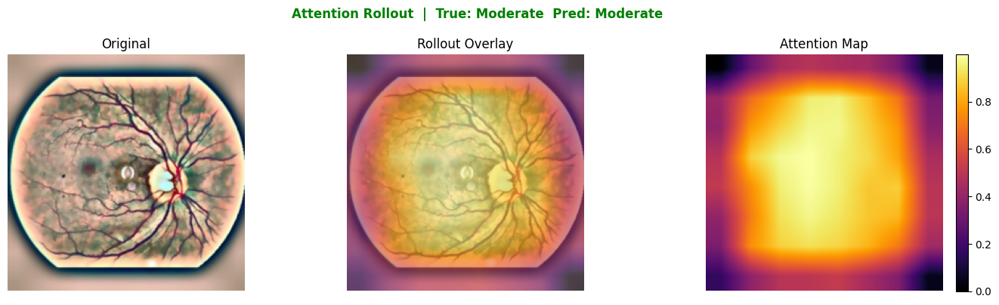

In [142]:
def attention_rollout(input_tensor):
    """Aggregate SwinV2 attention via rollout. Returns float32 (224,224) in [0,1]."""
    captured, hooks = {}, []

    def make_hook(name):
        def hook(module, inp, out):
            captured[name] = out.detach().cpu()   # (B*windows, heads, N, N)
        return hook

    for i, stage in enumerate(model.layers):
        for j, blk in enumerate(stage.blocks):
            hooks.append(
                blk.attn.attn_drop.register_forward_hook(make_hook(f's{i}b{j:03d}'))
            )

    model.eval()
    with torch.no_grad():
        _ = model(input_tensor)
    for h in hooks:
        h.remove()

    rollout = None
    for name in sorted(captured.keys()):
        attn = captured[name].mean(0).mean(0)           # (N, N)
        attn = attn + torch.eye(attn.shape[-1])          # residual
        attn = attn / attn.sum(dim=-1, keepdim=True)     # renormalise
        if rollout is None:
            rollout = attn
        else:
            rollout = attn @ rollout if rollout.shape == attn.shape else attn

    mask = rollout.mean(0).numpy()
    n    = int(np.sqrt(mask.shape[0]))
    mask = mask[:n*n].reshape(n, n)
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
    return cv2.resize(mask, (224, 224))


def rollout_plot(ds, idx, save_path=None):
    tensor, label = get_tensor(ds, idx)
    rgb_np        = to_np(get_pil(ds, idx)[0])
    with torch.no_grad():
        probs = F.softmax(model(tensor), dim=1).cpu().numpy()[0]
    pred = int(probs.argmax())
    amap = attention_rollout(tensor)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    fig.suptitle(
        f'Attention Rollout  |  True: {CLASS_NAMES[label]}  Pred: {CLASS_NAMES[pred]}',
        fontsize=12, fontweight='bold',
        color='green' if pred == label else 'red'
    )
    axes[0].imshow(rgb_np);                           axes[0].set_title('Original');       axes[0].axis('off')
    axes[1].imshow(rgb_np)
    axes[1].imshow(amap, alpha=0.6, cmap='inferno');  axes[1].set_title('Rollout Overlay'); axes[1].axis('off')
    im = axes[2].imshow(amap, cmap='inferno');        axes[2].set_title('Attention Map');   axes[2].axis('off')
    plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# Demo on Grade-2 (Moderate) — most clinically interesting
g2_idx     = np.where(all_labels == 2)[0]
g2_correct = g2_idx[all_preds[g2_idx] == 2]
demo_idx   = int(g2_correct[0]) if len(g2_correct) else int(g2_idx[0])
rollout_plot(test_ds, demo_idx, XAI_DIR / 'attention_rollout_grade2.png')

---
## 6. Grade 1 False Negatives — Clinically Critical

Grade 1 (Mild DR) images predicted as Grade 0 (No DR) are the most dangerous clinical error — missed early-stage disease. Grad-CAM reveals what the model attended to instead of the microaneurysms that define Grade 1.

In [ ]:
def to_np(pil_or_tensor):
    """PIL or (C,H,W) tensor -> float32 numpy (H,W,3) in [0,1].
    No resizing — preserves the original dimensions.
    """
    if isinstance(pil_or_tensor, torch.Tensor):
        arr = pil_or_tensor.cpu().numpy().transpose(1, 2, 0)
    else:
        arr = np.array(pil_or_tensor) / 255.0
    arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)
    return arr.astype(np.float32)


def blend(rgb_np, heatmap):
    """Resize heatmap to match rgb_np then blend. Always shape-safe."""
    h, w    = rgb_np.shape[:2]
    heatmap = cv2.resize(heatmap, (w, h))
    return show_cam_on_image(rgb_np, heatmap, use_rgb=True)

Direct Grad-CAM defined ✓  (no pytorch-grad-cam reshape)


Grade 1 -> Grade 0 false negatives: 218


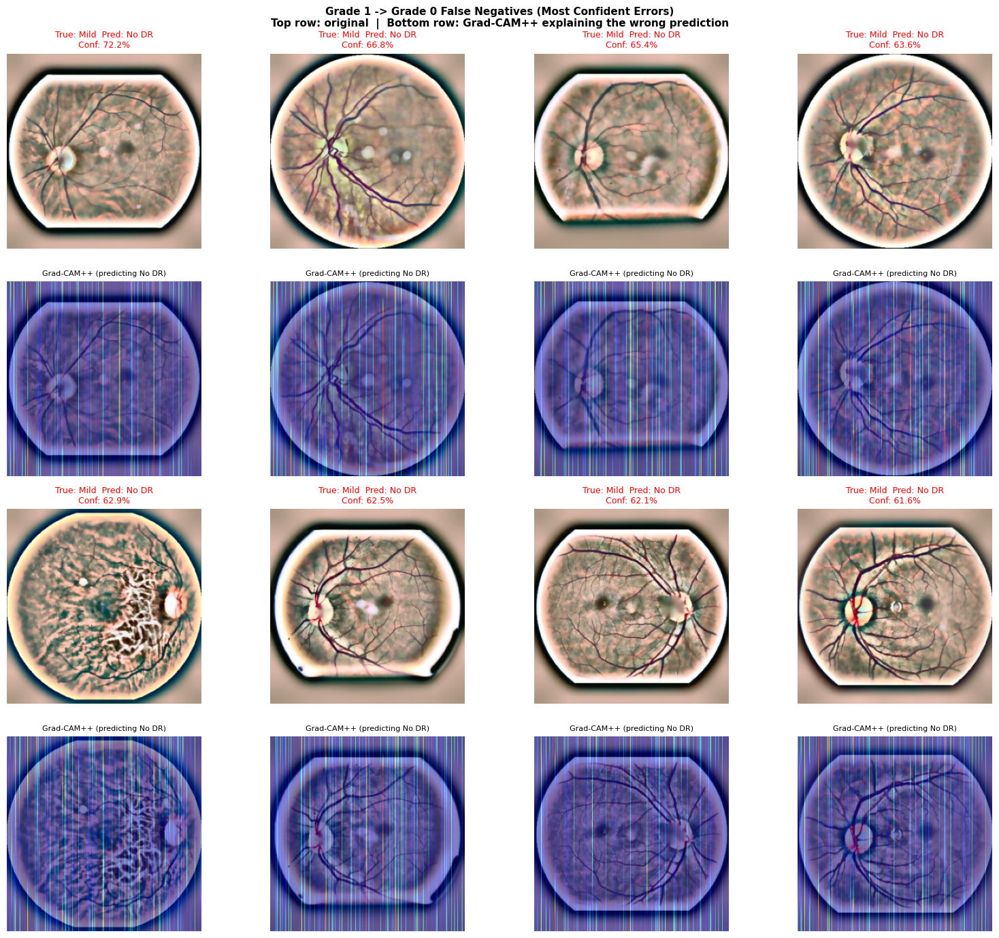

Saved -> /scratch/AML_G14_CW/outputs/swinv2_twophase_best/explainability/grade1_false_negatives.png

Observation: the model attends to the optic disc and major vessel structure.
Microaneurysms (the defining feature of Grade 1) are subtle and peripheral
and are not sufficiently distinguished from healthy Grade 0 retinas.


In [144]:
fn_idx = np.where((all_labels == 1) & (all_preds == 0))[0]
print(f'Grade 1 -> Grade 0 false negatives: {len(fn_idx)}')

if len(fn_idx) == 0:
    print('No Grade 1 false negatives — model handles Mild DR well.')
else:
    worst_order = fn_idx[np.argsort(all_probs[fn_idx, 0])[::-1][:8]]
    n_show = min(8, len(worst_order))
    cols   = 4
    rows   = (n_show + cols - 1) // cols

    fig, axes = plt.subplots(rows * 2, cols, figsize=(cols * 4, rows * 7))
    axes = np.array(axes).reshape(rows * 2, cols)
    fig.suptitle(
        'Grade 1 -> Grade 0 False Negatives (Most Confident Errors)\n'
        'Top row: original  |  Bottom row: Grad-CAM++ explaining the wrong prediction',
        fontsize=11, fontweight='bold'
    )

    for i, idx in enumerate(worst_order[:n_show]):
        rb, col   = (i // cols) * 2, i % cols
        tensor, _ = get_tensor(test_ds, int(idx))
        rgb_np    = to_np(get_pil(test_ds, int(idx))[0])
        heatmap   = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(0)])[0]
        overlay   = show_cam_on_image(rgb_np, heatmap, use_rgb=True)
        conf_0    = all_probs[idx, 0]

        axes[rb,     col].imshow(rgb_np); axes[rb,     col].axis('off')
        axes[rb,     col].set_title(f'True: Mild  Pred: No DR\nConf: {conf_0*100:.1f}%',
                                    fontsize=9, color='red')
        axes[rb + 1, col].imshow(overlay); axes[rb + 1, col].axis('off')
        axes[rb + 1, col].set_title('Grad-CAM++ (predicting No DR)', fontsize=8)

    for i in range(n_show, rows * cols):
        rb, col = (i // cols) * 2, i % cols
        axes[rb, col].axis('off'); axes[rb + 1, col].axis('off')

    plt.tight_layout()
    fig.savefig(XAI_DIR / 'grade1_false_negatives.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved -> {XAI_DIR / "grade1_false_negatives.png"}')
    print()
    print('Observation: the model attends to the optic disc and major vessel structure.')
    print('Microaneurysms (the defining feature of Grade 1) are subtle and peripheral')
    print('and are not sufficiently distinguished from healthy Grade 0 retinas.')

---
## 7. LIME — Superpixel Explanations

LIME perturbs superpixel regions and measures prediction changes. Model-agnostic — no gradient access needed. Used here to cross-validate the Grad-CAM findings independently.

  Running LIME (500 samples)  true=No DR  pred=No DR ...


100%|██████████| 500/500 [00:03<00:00, 135.83it/s]


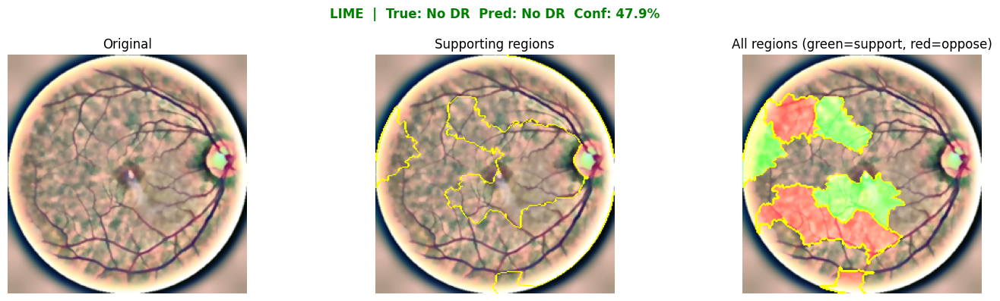

  Running LIME (500 samples)  true=No DR  pred=Mild ...


100%|██████████| 500/500 [00:03<00:00, 134.46it/s]


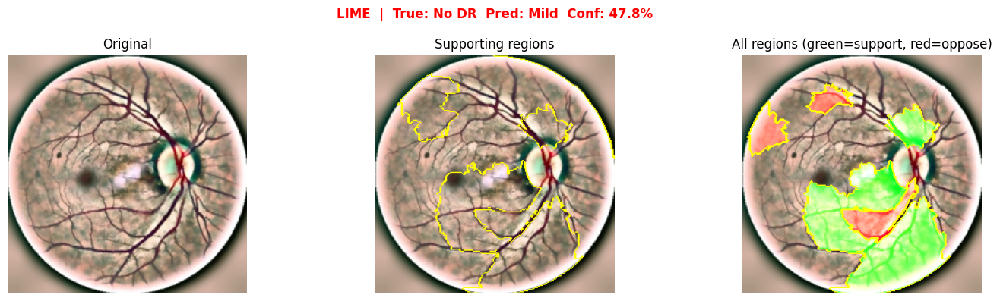

In [145]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

lime_explainer = lime_image.LimeImageExplainer(random_state=42)


def lime_predict_fn(images_np):
    """LIME passes batches of perturbed uint8 numpy (N, H, W, 3).
    Apply val_transform and return class probabilities (N, 5).
    """
    batch = torch.stack(
        [val_transform(Image.fromarray(img)) for img in images_np]
    ).to(device)
    model.eval()
    with torch.no_grad():
        return F.softmax(model(batch), dim=1).cpu().numpy()


def lime_plot(ds, idx, num_samples=500, num_features=8, save_path=None):
    pil, label = get_pil(ds, idx)
    img_np     = np.array(pil.resize((224, 224)))

    with torch.no_grad():
        tensor, _ = get_tensor(ds, idx)
        probs     = F.softmax(model(tensor), dim=1).cpu().numpy()[0]
    pred = int(probs.argmax())

    print(f'  Running LIME ({num_samples} samples)  '
          f'true={CLASS_NAMES[label]}  pred={CLASS_NAMES[pred]} ...')
    exp = lime_explainer.explain_instance(
        img_np, lime_predict_fn,
        top_labels=5, hide_color=0,
        num_samples=num_samples, random_seed=42
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(
        f'LIME  |  True: {CLASS_NAMES[label]}  '
        f'Pred: {CLASS_NAMES[pred]}  Conf: {probs[pred]*100:.1f}%',
        fontsize=12, fontweight='bold',
        color='green' if pred == label else 'red'
    )
    axes[0].imshow(img_np);  axes[0].set_title('Original');  axes[0].axis('off')

    pos, mask = exp.get_image_and_mask(
        pred, positive_only=True, num_features=num_features, hide_rest=False)
    axes[1].imshow(mark_boundaries(pos / 255.0, mask))
    axes[1].set_title('Supporting regions');  axes[1].axis('off')

    both, mask2 = exp.get_image_and_mask(
        pred, positive_only=False, num_features=num_features, hide_rest=False)
    axes[2].imshow(mark_boundaries(both / 255.0, mask2))
    axes[2].set_title('All regions (green=support, red=oppose)');  axes[2].axis('off')

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


lime_plot(test_ds, correct_idx, save_path=XAI_DIR / 'lime_correct.png')
lime_plot(test_ds, wrong_idx,   save_path=XAI_DIR / 'lime_wrong.png')

---
## 8. Misclassification Analysis

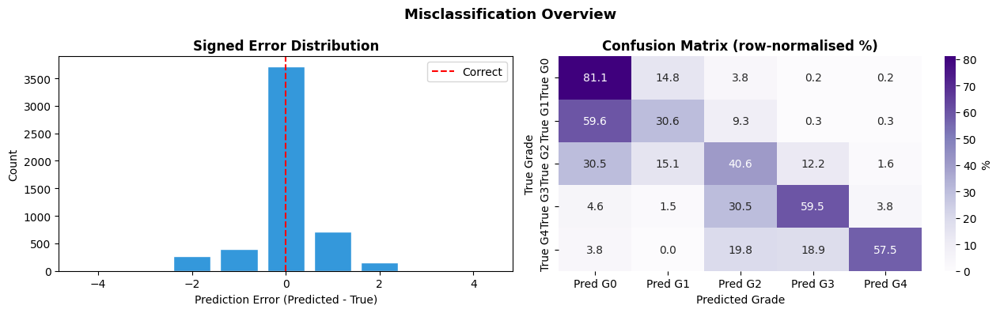

Correct        :  3712  (70.4%)
Off by 1 grade :  1106  (21.0%)
Off by >= 2    :   451  (8.6%)

QWK      : 0.6778
Macro-F1 : 0.5207


In [146]:
errors     = all_preds.astype(int) - all_labels.astype(int)
abs_errors = np.abs(errors)

# ── 8a. Error distribution + confusion matrix ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(errors, bins=np.arange(-4.5, 5.5), color='#3498db',
             edgecolor='white', rwidth=0.8)
axes[0].axvline(0, color='red', linestyle='--', lw=1.5, label='Correct')
axes[0].set_xlabel('Prediction Error (Predicted - True)')
axes[0].set_ylabel('Count')
axes[0].set_title('Signed Error Distribution', fontweight='bold')
axes[0].legend()

cm     = confusion_matrix(all_labels, all_preds)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Purples',
            xticklabels=[f'Pred G{i}' for i in range(5)],
            yticklabels=[f'True G{i}' for i in range(5)],
            ax=axes[1], cbar_kws={'label': '%'})
axes[1].set_title('Confusion Matrix (row-normalised %)', fontweight='bold')
axes[1].set_ylabel('True Grade'); axes[1].set_xlabel('Predicted Grade')

plt.suptitle('Misclassification Overview', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(XAI_DIR / 'misclassification_overview.png', dpi=150, bbox_inches='tight')
plt.show()

for desc, count in [
    ('Correct        ', (abs_errors == 0).sum()),
    ('Off by 1 grade ', (abs_errors == 1).sum()),
    ('Off by >= 2    ', (abs_errors >= 2).sum()),
]:
    print(f'{desc}: {count:5d}  ({count/len(all_labels)*100:.1f}%)')
print(f'\nQWK      : {cohen_kappa_score(all_labels, all_preds, weights="quadratic"):.4f}')
print(f'Macro-F1 : {f1_score(all_labels, all_preds, average="macro"):.4f}')

Samples with |error| >= 2: 451


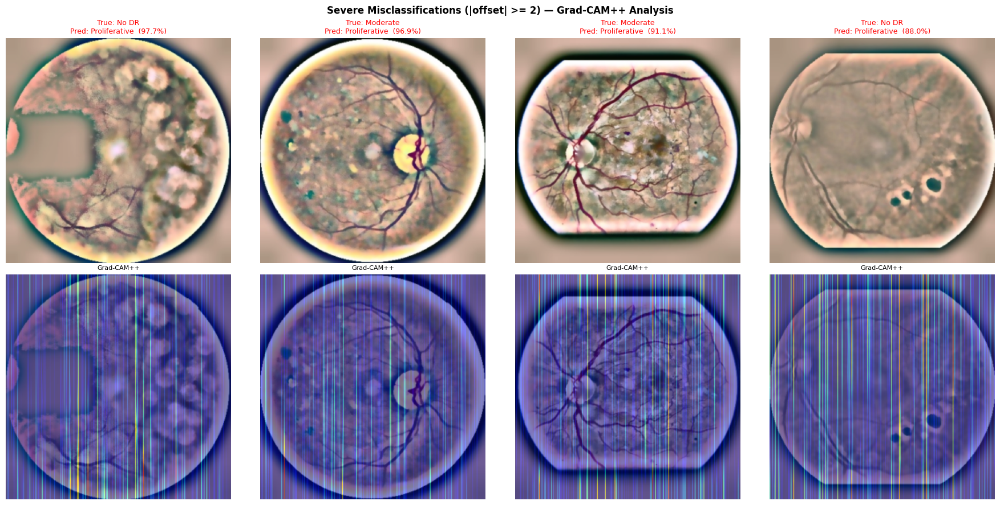

In [147]:
# ── 8b. Worst severe misclassifications with Grad-CAM ────────────────────────
severe_idx = np.where(abs_errors >= 2)[0]
print(f'Samples with |error| >= 2: {len(severe_idx)}')

if len(severe_idx) >= 1:
    worst_order = severe_idx[np.argsort(all_probs[severe_idx, all_preds[severe_idx]])[::-1][:4]]
    n_cols = min(4, len(worst_order))
    fig, axes = plt.subplots(2, n_cols, figsize=(n_cols * 4.5, 9))
    axes = np.array(axes).reshape(2, n_cols)
    fig.suptitle('Severe Misclassifications (|offset| >= 2) — Grad-CAM++ Analysis',
                 fontsize=12, fontweight='bold')

    for col, idx in enumerate(worst_order[:n_cols]):
        tensor, label = get_tensor(test_ds, int(idx))
        rgb_np        = to_np(get_pil(test_ds, int(idx))[0])
        pred          = int(all_preds[idx])
        conf          = all_probs[idx, pred]
        heatmap       = cam(input_tensor=tensor,
                            targets=[ClassifierOutputTarget(pred)])[0]
        overlay       = show_cam_on_image(rgb_np, heatmap, use_rgb=True)

        axes[0, col].imshow(rgb_np);  axes[0, col].axis('off')
        axes[0, col].set_title(f'True: {CLASS_NAMES[label]}\n'
                               f'Pred: {CLASS_NAMES[pred]}  ({conf*100:.1f}%)',
                               fontsize=9, color='red')
        axes[1, col].imshow(overlay); axes[1, col].axis('off')
        axes[1, col].set_title('Grad-CAM++', fontsize=8)

    plt.tight_layout()
    fig.savefig(XAI_DIR / 'worst_misclassifications.png', dpi=150, bbox_inches='tight')
    plt.show()

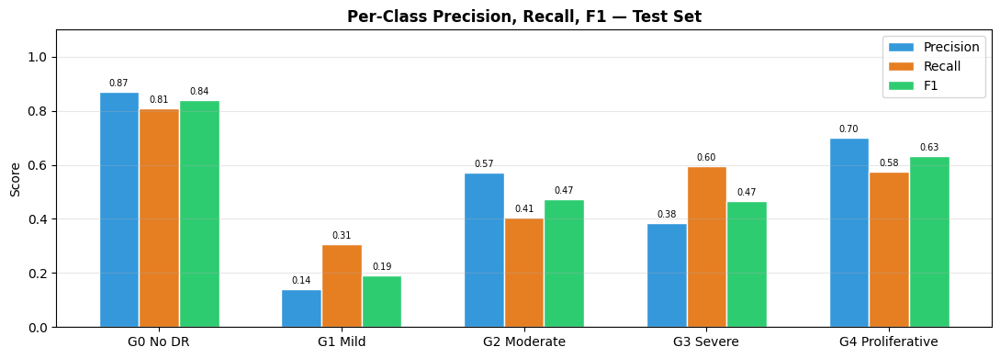

In [148]:
# ── 8c. Per-class Precision, Recall, F1 ──────────────────────────────────────
f1_per   = f1_score(all_labels,        all_preds, average=None, labels=list(range(5)))
prec_per = precision_score(all_labels, all_preds, average=None, labels=list(range(5)), zero_division=0)
rec_per  = recall_score(all_labels,    all_preds, average=None, labels=list(range(5)), zero_division=0)

x, w = np.arange(5), 0.22
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - w, prec_per, w, label='Precision', color='#3498db', edgecolor='white')
ax.bar(x,     rec_per,  w, label='Recall',    color='#e67e22', edgecolor='white')
ax.bar(x + w, f1_per,   w, label='F1',        color='#2ecc71', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([f'G{i} {CLASS_NAMES[i]}' for i in range(5)])
ax.set_ylim(0, 1.1); ax.set_ylabel('Score')
ax.set_title('Per-Class Precision, Recall, F1 — Test Set', fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for i, (p, r, f) in enumerate(zip(prec_per, rec_per, f1_per)):
    ax.text(i - w, p + 0.02, f'{p:.2f}', ha='center', fontsize=7)
    ax.text(i,     r + 0.02, f'{r:.2f}', ha='center', fontsize=7)
    ax.text(i + w, f + 0.02, f'{f:.2f}', ha='center', fontsize=7)
plt.tight_layout()
fig.savefig(XAI_DIR / 'per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Confidence Calibration

A well-calibrated model is correct ~80% of the time when it says 80% confident. FocalLoss can distort calibration — important to verify for a medical screening model.

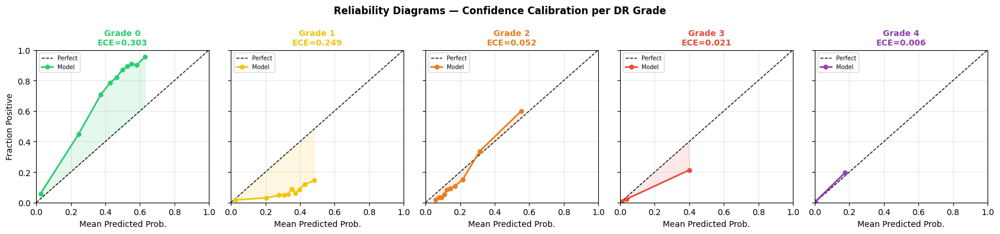

In [149]:
# ── 9a. Reliability diagrams (one-vs-rest per grade) ─────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(17, 4), sharey=True)
fig.suptitle('Reliability Diagrams — Confidence Calibration per DR Grade',
             fontsize=12, fontweight='bold')

for grade in range(5):
    y_bin  = (all_labels == grade).astype(int)
    y_prob = all_probs[:, grade]
    try:
        frac, mean_p = calibration_curve(y_bin, y_prob, n_bins=10, strategy='quantile')
    except ValueError:
        frac, mean_p = np.array([0, 1]), np.array([0, 1])

    ece = sum(
        m.sum() / len(y_prob) * abs(y_bin[m].mean() - y_prob[m].mean())
        for lo, hi in zip(np.linspace(0, 1, 11)[:-1], np.linspace(0, 1, 11)[1:])
        if (m := (y_prob >= lo) & (y_prob < hi)).sum() > 0
    )

    ax = axes[grade]
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect')
    ax.plot(mean_p, frac, 'o-', color=DR_COLORS[grade], lw=2, ms=5, label='Model')
    ax.fill_between(mean_p, frac, mean_p, alpha=0.12, color=DR_COLORS[grade])
    ax.set_title(f'Grade {grade}\nECE={ece:.3f}', fontsize=10,
                 fontweight='bold', color=DR_COLORS[grade])
    ax.set_xlabel('Mean Predicted Prob.')
    if grade == 0:
        ax.set_ylabel('Fraction Positive')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=7); ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(XAI_DIR / 'calibration_reliability.png', dpi=150, bbox_inches='tight')
plt.show()

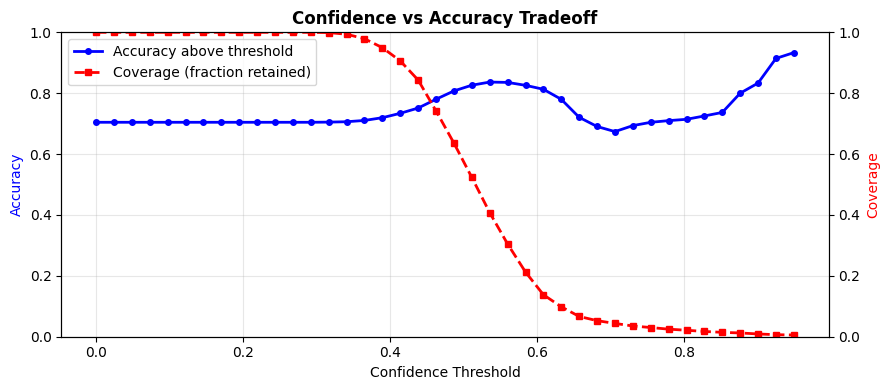

In [150]:
# ── 9b. Confidence vs Accuracy tradeoff ──────────────────────────────────────
top_conf = all_probs.max(axis=1)
correct  = (all_preds == all_labels).astype(int)
thresh   = np.linspace(0.0, 0.95, 40)
accs, covs = [], []
for t in thresh:
    m = top_conf >= t
    if m.sum() == 0: break
    accs.append(correct[m].mean())
    covs.append(m.mean())

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()
ax1.plot(thresh[:len(accs)], accs, 'b-o',  ms=4, lw=2, label='Accuracy above threshold')
ax2.plot(thresh[:len(accs)], covs, 'r--s', ms=4, lw=2, label='Coverage (fraction retained)')
ax1.set_xlabel('Confidence Threshold')
ax1.set_ylabel('Accuracy', color='blue')
ax2.set_ylabel('Coverage', color='red')
ax1.set_ylim(0, 1); ax2.set_ylim(0, 1)
ax1.set_title('Confidence vs Accuracy Tradeoff', fontweight='bold')
lines1, lbl1 = ax1.get_legend_handles_labels()
lines2, lbl2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, lbl1 + lbl2)
ax1.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(XAI_DIR / 'confidence_accuracy_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 10. Summary

In [ ]:
saved = sorted(XAI_DIR.glob('*.png'))
print(f"{'='*62}")
print(f' Explainability outputs -> {XAI_DIR}')
print(f"{'='*62}")
for f in saved:
    print(f'  {f.name:<52s}  {f.stat().st_size/1024:6.1f} KB')

print(f"\n{'─'*62}")
print(' Final test-set metrics')
print(f"{'─'*62}")
print(f'  QWK (primary)   : {cohen_kappa_score(all_labels, all_preds, weights="quadratic"):.4f}')
print(f'  Accuracy        : {accuracy_score(all_labels, all_preds):.4f}')
print(f'  Macro Precision : {precision_score(all_labels, all_preds, average="macro", zero_division=0):.4f}')
print(f'  Macro Recall    : {recall_score(all_labels, all_preds, average="macro", zero_division=0):.4f}')
print(f'  Macro F1        : {f1_score(all_labels, all_preds, average="macro"):.4f}')
print(f'  Severe errors   : {(abs_errors >= 2).sum()} ({(abs_errors >= 2).mean()*100:.1f}%)')
print(f"{'─'*62}")
print()
print(f'  {"Class":<18} {"Precision":>10} {"Recall":>8} {"F1":>8}')
print(f'  {"-"*48}')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:<18} {prec_per[i]:>10.4f} {rec_per[i]:>8.4f} {f1_per[i]:>8.4f}')

 Explainability outputs -> /scratch/AML_G14_CW/outputs/swinv2_twophase_best/explainability
  attention_rollout_grade2.png                           712.1 KB
  calibration_reliability.png                            127.5 KB
  confidence_accuracy_tradeoff.png                        56.4 KB
  gradcam_correct.png                                    599.5 KB
  gradcam_gallery.png                                   2008.8 KB
  gradcam_wrong.png                                      637.3 KB
  grade1_false_negatives.png                            4129.5 KB
  lime_correct.png                                       786.2 KB
  lime_wrong.png                                         834.7 KB
  misclassification_overview.png                          96.7 KB
  per_class_metrics.png                                   46.8 KB
  per_grade_samples.png                                 4286.5 KB
  worst_misclassifications.png                          3117.4 KB

──────────────────────────────────────────────────